# 02 · Preprocessing

Cuts E1-E4 (the last 15 s of each bin before awakening) from `eeg_120s` and cleans them with the October
pipeline: 0.5-30 Hz FIR, bad-channel interpolation, average re-reference, and 2-s sub-window rejection with one
robust threshold per sample, so E4 (which carries pre-waking movement) is judged by the same rule as E2.

Output: `derived/clean/<sample>.npz` (signal + rejected-sample mask per epoch), `results/tables/reject_rates.csv`.
Runtime: CPU, a few minutes. Resumable.

In [1]:
# Bootstrap: same cell in every notebook. On Colab: mount Drive, get the repo, install extras.
# The repo is private: add a read-only GitHub token to Colab Secrets as GH_TOKEN.
import os, sys, subprocess, base64
REPO_URL = "https://github.com/sanjanasinghx/dream2image-es606.git"
if "google.colab" in sys.modules and not os.environ.get("D2I_HEADLESS"):  # headless = run by d2i.runner
    from google.colab import drive, userdata
    drive.mount("/content/drive")
    REPO = "/content/dream2image-es606"
    try:
        auth = base64.b64encode(f"x-access-token:{userdata.get('GH_TOKEN')}".encode()).decode()
        git = ["git", "-c", f"http.extraHeader=Authorization: Basic {auth}"]  # token never written to disk
    except Exception:
        git = ["git"]  # no secret: works once the repo is public
    if not os.path.exists(REPO):
        subprocess.run([*git, "clone", "-q", REPO_URL, REPO], check=True)
    else:
        subprocess.run([*git, "-C", REPO, "pull", "-q"], check=True)
    freeze = lambda: subprocess.run([sys.executable, "-m", "pip", "freeze"], capture_output=True, text=True).stdout
    before = freeze()
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", f"{REPO}/requirements-colab.txt"], check=True)
    if freeze() != before:  # e.g. numpy upgraded under an already-loaded copy -> broken imports
        print("Packages changed: restarting the runtime. When it reconnects, Run all again.")
        os.kill(os.getpid(), 9)
else:
    REPO = os.path.abspath("..")
sys.path.insert(0, REPO)
from d2i import env
cfg = env.load_config()
rng = env.seed_everything(cfg["seed"])
print("data root:", env.data_root())

data root: /content/drive/MyDrive/ES606_Dream2Image


In [2]:
import json
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from joblib import Parallel, delayed
from d2i import data, preprocess
step0 = json.loads((env.path(cfg, "derived") / "step0.json").read_text())
channels = [c for c in step0["primary_channels"] if c not in cfg["preprocess"]["drop_channels"]]
out_dir = env.path(cfg, "derived") / "clean"; out_dir.mkdir(exist_ok=True)
tables = env.path(cfg, "results") / "tables"
figs = env.path(cfg, "results") / "figures"
print(len(step0["retained"]), "samples,", len(channels), "channels")

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


122 samples, 16 channels


In [3]:
def run(sid):
    arrays, recs, chans = preprocess.process_sample(cfg, sid, data.load_eeg(cfg, sid), channels)
    np.savez_compressed(out_dir / f"{sid}.npz", channels=np.array(channels), **arrays)
    pd.DataFrame(recs).to_csv(out_dir / f"{sid}_epochs.csv", index=False)
    pd.DataFrame(chans).to_csv(out_dir / f"{sid}_channels.csv", index=False)
    return sid

todo = [s for s in step0["retained"] if not (out_dir / f"{s}_channels.csv").exists()]
print(f"{len(todo)} samples to process")
Parallel(n_jobs=-1, verbose=5)(delayed(run)(s) for s in todo)

122 samples to process


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 2 concurrent workers.


[Parallel(n_jobs=-1)]: Done  14 tasks      | elapsed:   13.6s


[Parallel(n_jobs=-1)]: Done  68 tasks      | elapsed:   31.5s


[Parallel(n_jobs=-1)]: Done 122 out of 122 | elapsed:   47.4s finished


['s000',
 's001',
 's002',
 's003',
 's004',
 's005',
 's006',
 's007',
 's008',
 's009',
 's010',
 's011',
 's012',
 's013',
 's014',
 's015',
 's016',
 's017',
 's018',
 's019',
 's020',
 's021',
 's024',
 's025',
 's027',
 's028',
 's029',
 's030',
 's031',
 's032',
 's033',
 's034',
 's035',
 's036',
 's037',
 's038',
 's039',
 's040',
 's041',
 's042',
 's043',
 's044',
 's045',
 's046',
 's047',
 's048',
 's049',
 's050',
 's051',
 's052',
 's053',
 's055',
 's056',
 's057',
 's058',
 's059',
 's060',
 's061',
 's062',
 's063',
 's064',
 's065',
 's066',
 's067',
 's068',
 's069',
 's070',
 's071',
 's073',
 's074',
 's075',
 's076',
 's077',
 's078',
 's079',
 's080',
 's081',
 's082',
 's083',
 's084',
 's085',
 's086',
 's087',
 's088',
 's090',
 's091',
 's092',
 's093',
 's094',
 's095',
 's096',
 's097',
 's098',
 's099',
 's100',
 's101',
 's102',
 's103',
 's104',
 's105',
 's106',
 's107',
 's108',
 's109',
 's110',
 's111',
 's112',
 's113',
 's114',
 's116',
 's117',
 

In [4]:
excl = pd.read_csv(tables / "sample_exclusions.csv")
rej = pd.concat([pd.read_csv(out_dir / f"{s}_epochs.csv") for s in step0["retained"]])
rej = rej.merge(excl[["sample_id", "participant", "site", "tag_class"]], on="sample_id")
chq = pd.concat([pd.read_csv(out_dir / f"{s}_channels.csv") for s in step0["retained"]])
rej.to_csv(tables / "reject_rates.csv", index=False)
chq.to_csv(tables / "channel_quality.csv", index=False)
summary = rej.groupby("epoch").agg(n=("reject_rate", "size"), reject_mean=("reject_rate", "mean"),
                                   frac_any_reject=("reject_rate", lambda s: (s > 0).mean()),
                                   interp_mean=("n_interp", "mean"), unusable=("usable", lambda s: (~s).sum()))
summary.round(3).to_csv(tables / "reject_summary.csv")
print(summary.round(3))
print("sample-level bad channels:", chq.bad_reason.value_counts().to_dict())

         n  reject_mean  frac_any_reject  interp_mean  unusable
epoch                                                          
E1      22        0.134            0.455        0.364         0
E2     122        0.122            0.475        0.910         5
E3     122        0.097            0.385        0.877         4
E4     122        0.126            0.508        0.885         4
sample-level bad channels: {'low_neighbor_r': 105}


PosixPath('/content/drive/MyDrive/ES606_Dream2Image/results/logs/manifest_02_preprocess.json')

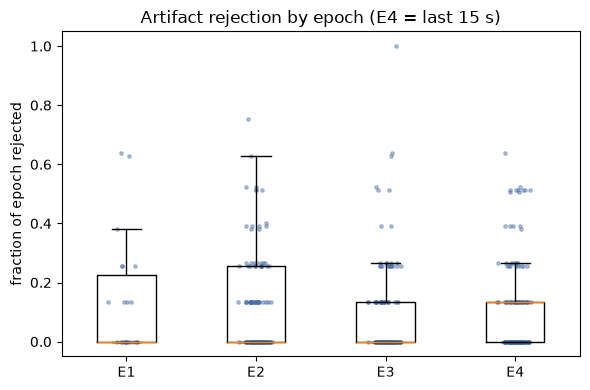

In [5]:
fig, ax = plt.subplots(figsize=(6, 4))
order = ["E1", "E2", "E3", "E4"]
ax.boxplot([rej.loc[rej.epoch == e, "reject_rate"] for e in order], tick_labels=order, showfliers=False)
for i, e in enumerate(order, 1):
    y = rej.loc[rej.epoch == e, "reject_rate"]
    ax.scatter(np.random.default_rng(0).normal(i, .06, len(y)), y, s=6, alpha=.4, color="#4a6fa5")
ax.set(ylabel="fraction of epoch rejected", title="Artifact rejection by epoch (E4 = last 15 s)")
fig.tight_layout(); fig.savefig(figs / "reject_by_epoch.pdf"); fig.savefig(figs / "reject_by_epoch.png", dpi=150)
env.write_manifest(cfg, "02_preprocess", [tables / "reject_rates.csv", tables / "channel_quality.csv",
                                          tables / "reject_summary.csv"],
                   notes={"n_clean_files": len(list(out_dir.glob("s*.npz"))), "channels": channels})